# 항공 분야 채용공고 텍스트 분석
### 공고 제목에서 키워드·직무·고용형태를 뽑아 채용 흐름 읽기 — 정제 · 키워드 · 직무 사전 · 트렌드

**환경:** Google Colab (인터넷 연결 필요)
**준비물 (파일 1개)**
| 파일 | 내용 |
|---|---|
| 채용공고 `.csv` 파일 | 항공 분야 채용공고 9,995건 (시작일자, 종료일자, **채용정보**(공고 제목), 회사, 주소, 홈페이지) |

**소요 시간:** 약 40분

## 오늘의 상황
> 취업을 준비할 때 "요즘 어떤 직무를 많이 뽑지?", "신입을 뽑는 분야는 어디지?"가 궁금합니다.
> 수천 건의 채용공고 제목을 텍스트로 분석하면, **많이 뽑는 직무, 늘어나는 분야, 신입·경력 비율, 지역별 차이**를 한눈에 볼 수 있습니다.

## 실습 진행 과정
| 단계 | 할 일 | 산출물 |
|---|---|---|
| 0. 준비 | 설치, `cp949`로 파일 읽기 | 원본 표 |
| 1. 텍스트 전처리 | 태그·고용형태·지역 열 뽑기 → 제목 정리 → 반복 공고 제거 → 키워드 뽑기 | 처리 전/후 비교 |
| 2. 정제 데이터셋 | 직무 사전으로 직무 태그 달기, 저장 | `job_dataset.csv` |
| 3. 텍스트 분석 | 키워드 TOP 20·워드클라우드, 2-gram, 직무별 건수, 직무별 대표 키워드 | 그래프·표 |
| 4. 분석 결과 | 연도별 직무 변화, 연도별 특징 키워드, 지역 × 직무, 고용형태, 회사 TOP 10 | 그래프 4개, 표 |
| 정리 | 한계 | — |

> **실행 방법:** 셀을 클릭하고 `Shift + Enter`. 반드시 **위에서부터 순서대로** 실행하세요.
> ✏️ 표시가 있는 곳은 **직접 바꿔 볼 수 있는 부분**입니다.

---
## 0. 준비
| 도구 | 하는 일 |
|---|---|
| `kiwipiepy` | 한국어 형태소 분석기 Kiwi (명사 뽑기) |
| `koreanize-matplotlib` | 그래프에 한글 글꼴(나눔고딕) 설정 |
| `wordcloud` | 워드클라우드 (Colab에 기본 설치) |
| `scikit-learn` | 단어 묶음 세기, TF-IDF (Colab에 기본 설치) |

In [ ]:
# 도구 설치 (처음 한 번만 실행)
# !     : 파이썬 코드가 아니라 리눅스 명령어를 실행하라는 표시
# pip install : 파이썬 도구(패키지)를 인터넷에서 내려받아 설치하는 명령어
# -q    : 설치 과정 메시지를 짧게 줄여서 보여 줌
# kiwipiepy           : 한국어 형태소 분석기 Kiwi
# koreanize-matplotlib : 그래프 한글 글꼴(나눔고딕) 자동 설정 도구
# wordcloud           : 워드클라우드 그리는 도구
!pip install -q kiwipiepy koreanize-matplotlib wordcloud

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.9/87.9 MB 8.3 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.6/11.6 MB 50.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.9/7.9 MB 49.5 MB/s eta 0:00:00


> 🔧 다음 셀에서 `PIL` 관련 `ImportError`가 나면: 메뉴 **런타임 → 세션 다시 시작** 후 설치 셀은 건너뛰고 다음 셀부터 실행하세요.

Colab 왼쪽 **📁 파일 창**에 **채용공고 `.csv` 파일**을 끌어다 놓으세요. 이 파일은 공공기관 CSV에 흔한 `cp949`(완성형 한글) 방식으로 저장되어 있어서 `encoding="cp949"`로 읽습니다.

In [ ]:
import glob                 # 파일 이름을 패턴(예: *.csv)으로 찾는 도구
import pandas as pd         # 표(DataFrame)를 다루는 도구, pd라는 짧은 이름으로 부름

# 지금 폴더의 .csv 파일 중 이 실습에서 만드는 파일이 아닌 것 = 원본 파일
#   glob.glob("*.csv")        : 지금 폴더에서 이름이 .csv로 끝나는 파일 목록
#   if p != "job_dataset.csv" : 실습 결과 파일(job_dataset.csv)은 목록에서 뺌
#                               (다시 실행할 때 실습 결과 파일을 원본으로 잘못 고르지 않게 이름을 빼 둠)
#   [0]                       : 남은 목록의 첫 번째 파일 이름
raw_path = [p for p in glob.glob("*.csv") if p != "job_dataset.csv"][0]

# 원본 읽기 (encoding="cp949": 이 파일의 한글 저장 방식)
#   pd.read_csv : CSV 파일을 읽어서 표(DataFrame)로 만듦
raw = pd.read_csv(raw_path, encoding="cp949")

# 시작일자 앞 4글자 = 공고 연도
#   raw["시작일자"] : '시작일자' 열 (예: '2024-03-15')
#   .str[:4]        : 글자마다 앞에서 4글자만 잘라냄 (예: '2024')
#   raw["연도"] = … : 잘라낸 값을 '연도'라는 새 열로 저장
raw["연도"] = raw["시작일자"].str[:4]

# 파일 이름, 공고 수(len: 행 개수), 회사 수(nunique: 서로 다른 값의 개수) 출력
print("파일:", raw_path, "/ 공고 수:", len(raw), "/ 회사 수:", raw["회사"].nunique())
# 가장 이른 시작일자(min)와 가장 늦은 시작일자(max) 출력
print("기간:", raw["시작일자"].min(), "~", raw["시작일자"].max())
# 열 4개만 골라서 위에서 5줄(head) 보여 주기
raw[["시작일자", "채용정보", "회사", "주소"]].head()

파일: 국토교통부_항공일자리_채용_20251231.csv / 공고 수: 9995 / 회사 수: 1428
기간: 2018-10-23 ~ 2025-12-31


,시작일자,채용정보,회사,주소
0,2018-10-23,[상시채용]항공사 경력 기장 채용,에어부산,부산광역시 강서구 유통단지1로57번가길 6 (대저2동)
1,2018-11-05,[경력] 고경력 부기장 (기장승격훈련요원)(1),에어부산,부산광역시 강서구 유통단지1로57번가길 6 (대저2동)
2,2018-11-08,미국항공정비사취업,아퀼라인터내셔널,서울특별시 강서구 방화대로33길 3 (방화동)
3,2018-11-16,[상시채용] 군경력조종사 채용(1),에어부산,부산광역시 강서구 유통단지1로57번가길 6 (대저2동)
4,2018-11-19,경력 운항관리사 상시 채용(1),에어서울,인천광역시 중구 공항로 272 (운서동)


---
## 1. 텍스트 데이터 전처리

### 💡 이 데이터의 특징
| 특징 | 예 | 처리 방법 |
|---|---|---|
| 텍스트가 **공고 제목뿐** (평균 20글자) | `회전익 조종사 채용` | 제목에서 최대한 정보 뽑기 |
| 대괄호 태그 | `[경력]`, `[인천공항]`, `[상시채용]` | `태그` 열로 뽑고 제목에서 지우기 |
| 고용형태가 제목 안에 섞여 있음 | `신입/경력`, `계약직`, `인턴` | `고용형태` 열 만들기 |
| 차수·연도 표기 | `2024년 7차`, `’24년 14차` | 지우기 |
| **같은 공고를 여러 번** 올림 | 상시채용·재공고 | 회사+제목이 같으면 하나만 |

### 1-1. 태그·고용형태·지역 열 뽑기

In [ ]:
import re                   # 정규식(글자 패턴 찾기·바꾸기) 도구

# ① 대괄호 태그: [ ] 안의 글자를 모두 찾아(findall) 쉼표로 이어 붙이기
#   \[ \] : 대괄호 글자 자체,  [^\]]+ : ']'가 아닌 글자 1개 이상 → 괄호 ( )로 묶어 꺼냄
#   .str.findall(…)   : 제목마다 패턴에 맞는 부분을 모두 찾아 목록으로 만듦 (예: ['경력', '인천공항'])
#   .str.join(", ")   : 목록을 쉼표+공백으로 이어 한 글자로 만듦 (예: '경력, 인천공항'), 없으면 빈 글자
raw["태그"] = raw["채용정보"].str.findall(r"\[([^\]]+)\]").str.join(", ")

# ② 고용형태: {이름: 찾을 표현} → 제목에 표현이 있으면 그 이름을 붙임 (여러 개 가능)
# ✏️ 고용형태 사전
#   | : 정규식에서 '또는' (예: r"계약|기간제|임기제" → 셋 중 하나라도 있으면 해당)
EMPLOY = {"신입": r"신입", "경력": r"경력", "인턴": r"인턴", "정규직": r"정규",
          "계약직": r"계약|기간제|임기제", "아르바이트": r"아르바이트|알바|시간제|단기"}
# .apply(lambda t: …)    : 제목(t) 하나하나에 아래 계산을 적용
#   EMPLOY.items()       : (이름, 표현) 쌍을 하나씩 꺼냄
#   re.search(pat, t)    : 제목 t 안에 표현 pat이 있으면 찾은 결과, 없으면 None
#   ", ".join(…)         : 표현이 있는 이름만 모아 쉼표로 이음 (예: '신입, 경력'), 하나도 없으면 빈 글자
raw["고용형태"] = raw["채용정보"].apply(
    lambda t: ", ".join(name for name, pat in EMPLOY.items() if re.search(pat, t)))   # 해당하는 이름을 쉼표로 이음

# ③ 지역: 주소의 첫 단어(예: '인천광역시') → 국내 17개 시·도가 아니면 '해외·기타'
#   KOREA : 시·도 이름의 앞부분 목록 (예: '경상남'은 '경상남도'와 맞음)
KOREA = ["서울", "부산", "대구", "인천", "광주", "대전", "울산", "세종", "경기", "강원",
         "충청북", "충청남", "전북", "전라북", "전라남", "경상북", "경상남", "제주"]
# 주소의 첫 단어 꺼내기
#   .fillna("")      : 빈 주소(NaN)를 빈 글자로 바꿈
#   .str.split()     : 공백 기준으로 나눠 단어 목록으로 만듦
#   .str[0]          : 목록의 첫 번째 단어 (빈 목록이면 NaN)
#   .fillna("")      : 첫 단어가 없어서 생긴 NaN을 다시 빈 글자로 바꿈
first = raw["주소"].fillna("").str.split().str[0].fillna("")              # 주소를 공백으로 나눈 첫 단어
# 첫 단어가 KOREA 중 하나로 시작하면 그대로, 아니면 '해외·기타'
#   w.startswith(k)          : 단어 w가 k로 시작하면 True
#   any(…)                   : KOREA 중 하나라도 True면 True
#   first.where(조건, 값)    : 조건이 True인 칸은 그대로 두고, False인 칸은 값('해외·기타')으로 바꿈
raw["지역"] = first.where(first.apply(lambda w: any(w.startswith(k) for k in KOREA)), "해외·기타")

# 원래 제목과 새로 만든 열 3개를 무작위로 5줄 보여 주기 (random_state=2: 실행할 때마다 같은 5줄이 나옴)
raw[["채용정보", "태그", "고용형태", "지역"]].sample(5, random_state=2)

,채용정보,태그,고용형태,지역
7352,기체개발파트 경력직 채용,,경력,인천광역시
5686,비상임이사 공모,,,인천광역시
8284,제주국제공항 항공화물 탑재관리직 채용공고,,,제주특별자치도
3035,대한항공예약발권 상담사,,,서울특별시
6806,2024년 7차 신입/경력/아르바이트 채용,,"신입, 경력, 아르바이트",경상남도


### 1-2. 제목 정리 + 반복 공고 제거

In [ ]:
# 제목 하나 → 정리된 제목
#   re.sub(패턴, 바꿀 글자, 원래 글자) : 원래 글자에서 패턴에 맞는 부분을 모두 바꿈
def clean(title):
    # 대괄호 태그 지우기 (이미 열로 뽑아 둠)
    #   \[[^\]]*\] : '['로 시작해서 ']'가 아닌 글자 0개 이상, ']'로 끝나는 부분 → 공백
    title = re.sub(r"\[[^\]]*\]", " ", title)                            # 대괄호 태그 지우기 (이미 열로 뽑아 둠)
    # 연도(2024년, ’24년)·차수(7차)·인원(3명) 지우기
    #   [’'‘]?\d{2,4}\s*년        : 따옴표(있어도 없어도 됨) + 숫자 2~4개 + 공백(있어도 됨) + '년'
    #   \d+\s*(차|기|명|월|일)     : 숫자 1개 이상 + 공백(있어도 됨) + 차·기·명·월·일 중 하나
    title = re.sub(r"[’'‘]?\d{2,4}\s*년|\d+\s*(차|기|명|월|일)", " ", title)   # 연도(2024년, ’24년)·차수(7차)·인원(3명) 지우기
    # 한글·영어가 아닌 글자(숫자, /, ·, 괄호) → 공백
    #   [^가-힣A-Za-z] : 한글(가~힣)과 영어 대·소문자가 아닌 글자 1개
    title = re.sub(r"[^가-힣A-Za-z]", " ", title)                          # 한글·영어가 아닌 글자(숫자, /, ·, 괄호) → 공백
    # 여러 칸 공백을 한 칸으로, 앞뒤 공백 지우기
    #   \s+     : 공백 1개 이상
    #   .strip() : 맨 앞과 맨 뒤의 공백 지우기
    return re.sub(r"\s+", " ", title).strip()                             # 여러 칸 공백을 한 칸으로, 앞뒤 공백 지우기

# 모든 공고 제목(채용정보)에 clean을 적용해서 '제목' 열로 저장
raw["제목"] = raw["채용정보"].apply(clean)

# 처리 전/후 비교 5개 (원래 제목과 정리된 제목을 무작위로 5줄, random_state=5: 매번 같은 5줄)
raw[["채용정보", "제목"]].sample(5, random_state=5)

,채용정보,제목
5374,싱가포르 창이공항 지상직 체크인 카운터 채용,싱가포르 창이공항 지상직 체크인 카운터 채용
8037,2024년 하반기 직원 채용 공고,하반기 직원 채용 공고
4929,신입/경력사원 채용 - 항공소재 사업 담당,신입 경력사원 채용 항공소재 사업 담당
1990,임원 후보자 모집 공고,임원 후보자 모집 공고
4501,첨단모빌리티산업과장 개방형직위 임용시험 공고,첨단모빌리티산업과장 개방형직위 임용시험 공고


In [ ]:
# 회사와 정리된 제목이 둘 다 같은 공고는 첫 번째 것만 남기기 (같은 공고를 다시 올린 것으로 봄)
#   drop_duplicates(["회사", "제목"]) : 두 열 값이 모두 같은 행 중 첫 행만 남기고 나머지 지우기
#   reset_index(drop=True)            : 행 번호를 0, 1, 2, … 로 다시 매기기 (예전 번호는 버림)
df = raw.drop_duplicates(["회사", "제목"]).reset_index(drop=True)
# 지우기 전 공고 수와 지운 뒤 공고 수 출력
print("반복 공고 제거:", len(raw), "건 →", len(df), "건")

# 제거 전후 '공고가 많은 회사 TOP 5' 비교 (value_counts: 회사별 개수)
#   raw["회사"].value_counts().head(5)       : 지우기 전 공고가 많은 회사 5곳과 공고 수
#   df["회사"].value_counts().reindex(…)     : 지운 뒤 회사별 공고 수를, 지우기 전 TOP 5 회사 순서대로 꺼냄
#   pd.DataFrame({열 이름: 값, …})           : 두 결과를 나란히 놓은 표 만들기
pd.DataFrame({"제거 전": raw["회사"].value_counts().head(5),
              "제거 후": df["회사"].value_counts().reindex(raw["회사"].value_counts().head(5).index)})

반복 공고 제거: 9995 건 → 7711 건


,제거 전,제거 후
회사,,
샤프에비에이션케이,447,228
에이티에스,192,86
에어로케이,183,157
스위스포트코리아,150,97
에어프레미아,142,133


✅ **결과 확인:** 상시채용을 하는 회사는 같은 제목을 수백 번 올렸습니다. 지우지 않으면 이 회사들이 키워드와 직무 순위를 크게 끌어올립니다.

### 1-3. 키워드 뽑기 (명사 + 불용어 + 표기 통일)
**✏️ 불용어 `STOP`**: 모든 공고에 나오는 말(`채용`, `모집`)과, 따로 분석하는 고용형태(`신입`, `경력`)는 키워드에서 뺍니다.

In [ ]:
from kiwipiepy import Kiwi   # 한국어 형태소 분석기
kiwi = Kiwi()                  # 분석기 준비 (처음 한 번 몇 초 걸림)

# ✏️ 불용어: 키워드에서 뺄 말
#   { } : 집합(set), 'w not in STOP'처럼 들어 있는지 빠르게 확인할 때 씀
STOP = {"채용", "모집", "공고", "공개", "직원", "사원", "인력", "근로자", "항공",
        "직", "팀", "부", "원", "급", "사", "분야", "부문", "본부", "업무", "담당", "담당자",
        "상반기", "하반기", "수시", "상시", "신규", "기간", "경쟁", "위촉",
        "신입", "경력", "인턴", "정규직", "계약직", "계약"}

# ✏️ 표기 통일: {바꿀 말: 통일할 말}
NORM = {"인천국제공항": "인천공항", "제주국제공항": "제주공항", "김포국제공항": "김포공항", "김해국제공항": "김해공항"}

# 제목 하나 → 키워드 목록
#   t.tag in (...)    : 일반명사·고유명사·외국어만
#   영어(SL)는 대문자로 통일 (uam, UAM → UAM)
#   len(w) >= 2       : 한 글자짜리는 뜻이 불분명해서 뺌
def to_keywords(title):
    # kiwi.tokenize(title) : 제목을 형태소(뜻을 가진 가장 작은 말 덩어리) 목록으로 나눔
    #   t.form : 형태소 글자 (예: '정비사'),  t.tag : 품사 (NNG 일반명사, NNP 고유명사, SL 외국어)
    #   t.form.upper() if t.tag == "SL" else t.form : 외국어면 대문자로, 아니면 그대로
    words = [t.form.upper() if t.tag == "SL" else t.form
             for t in kiwi.tokenize(title) if t.tag in ("NNG", "NNP", "SL")]
    # NORM.get(w, w) : w가 NORM에 있으면 통일할 말로, 없으면 w 그대로
    words = [NORM.get(w, w) for w in words]
    # 2글자 이상이고 불용어가 아닌 말만 남겨서 돌려줌
    return [w for w in words if len(w) >= 2 and w not in STOP]

# 모든 제목 → 키워드 목록 (10초 정도 걸림)
#   df["제목"].apply(to_keywords) : 제목마다 to_keywords를 적용, 결과(목록)를 '키워드' 열로 저장
df["키워드"] = df["제목"].apply(to_keywords)
# 0번, 100번, 2000번 공고의 제목과 키워드 목록을 출력해서 확인
for i in [0, 100, 2000]:
    print(df["제목"][i], "→", df["키워드"][i])

항공사 경력 기장 채용 → ['항공사', '기장']
인천공항 항공 수하물 조업직 모집 운전면허 소지자 → ['인천공항', '수하물', '조업직', '운전', '면허', '소지자']
항공안전처 항공장애 표시등 검사업무 위촉연구원 채용 → ['안전처', '장애', '표시', '검사', '연구원']


---
## 2. 정제 데이터셋

### 직무 사전으로 직무 태그 달기
**✏️ 직무 사전 `JOBS`**: 제목에 표현이 하나라도 있으면 그 직무를 붙입니다. **한 공고에 여러 직무가 붙을 수 있습니다**(예: `드론 교관` → 드론·UAM, 교육). 아무것도 안 걸리면 `미분류`입니다.

In [ ]:
# ✏️ 직무 사전 {직무: 찾을 표현(정규식, | 는 '또는')}
JOBS = {
    "지상조업·여객서비스": r"지상|조업|수하물|램프|탑재|발권|예약|카운터|라운지|여객|운송|화물|상담",
    "드론·UAM":          r"드론|무인|UAM|도심항공",
    "연구·개발":          r"연구|개발|설계|해석|소프트웨어|하드웨어|엔지니어",
    "정비":              r"정비|MRO|기체|엔진",
    "사무·경영":          r"사무|행정|경영|회계|인사|총무|마케팅|구매|영업|재무|기획",
    "조종·운항":          r"조종|기장|운항|비행|파일럿",
    "교육":              r"교관|강사|교원|교수|교육",
    "보안·검색":          r"보안|검색|경비",
    "식음·기내식":        r"기내식|조리|식당|케이터링",
    "객실승무원":         r"승무원|객실",
}
# 그래프에 늘어놓을 순서
#   list(JOBS)          : 사전의 직무 이름만 꺼낸 목록 (사전에 적은 순서 그대로)
#   + ["미분류"]        : 맨 끝에 '미분류'를 붙임
ORDER = list(JOBS) + ["미분류"]          # 그래프에 늘어놓을 순서

# 제목 하나 → 해당하는 직무 목록 (없으면 ['미분류'])
def find_jobs(title):
    # JOBS.items() 에서 (직무, 표현)을 하나씩 꺼내, 제목에 표현이 있는 직무만 목록으로 모음
    jobs = [job for job, pat in JOBS.items() if re.search(pat, title)]
    # 목록이 비어 있지 않으면 그 목록, 비어 있으면 ['미분류']
    return jobs if jobs else ["미분류"]

# 정리된 제목마다 find_jobs를 적용해서 '직무' 열(목록)로 저장
df["직무"] = df["제목"].apply(find_jobs)

# 정제 데이터셋 저장 (목록 열은 쉼표로 이은 글자로 바꿔 저장, utf-8-sig: 엑셀에서 한글이 안 깨지게)
#   df[[…]].copy()        : 저장할 열 8개만 골라 복사본 만들기 (원래 df는 그대로)
out = df[["연도", "시작일자", "회사", "지역", "채용정보", "제목", "태그", "고용형태"]].copy()
# 키워드 목록 → '항공기, 정비사' 같은 한 글자로 바꿔 '키워드' 열로 넣기
out["키워드"] = df["키워드"].str.join(", ")
# 직무 목록 → '드론·UAM, 교육' 같은 한 글자로 바꿔 '직무' 열로 넣기
out["직무"] = df["직무"].str.join(", ")
# CSV 파일로 저장 (index=False: 행 번호는 저장하지 않음)
out.to_csv("job_dataset.csv", index=False, encoding="utf-8-sig")

# 저장한 파일 이름과 공고 수 출력
print("저장 완료: job_dataset.csv /", len(out), "건")
# 정리된 제목·고용형태·직무 열을 무작위로 5줄 보여 주기 (random_state=1: 매번 같은 5줄)
out[["제목", "고용형태", "직무"]].sample(5, random_state=1)

저장 완료: job_dataset.csv / 7711 건


,제목,고용형태,직무
6386,Air Admin Assistant I Air Operations,,미분류
442,공항 관리직 모집,,미분류
4089,계약직원 모집 연구지원팀 SW중점대학 사업단,계약직,연구·개발
130,전문인력 채용,,미분류
1685,제 사업본부 계약직 수시채용,계약직,미분류


---
## 3. 텍스트 분석

### 3-1. 키워드 TOP 20 + 워드클라우드
제목이 짧아서 같은 공고 안에서 같은 단어가 반복되는 일이 거의 없으므로, **등장 횟수**로 셉니다.

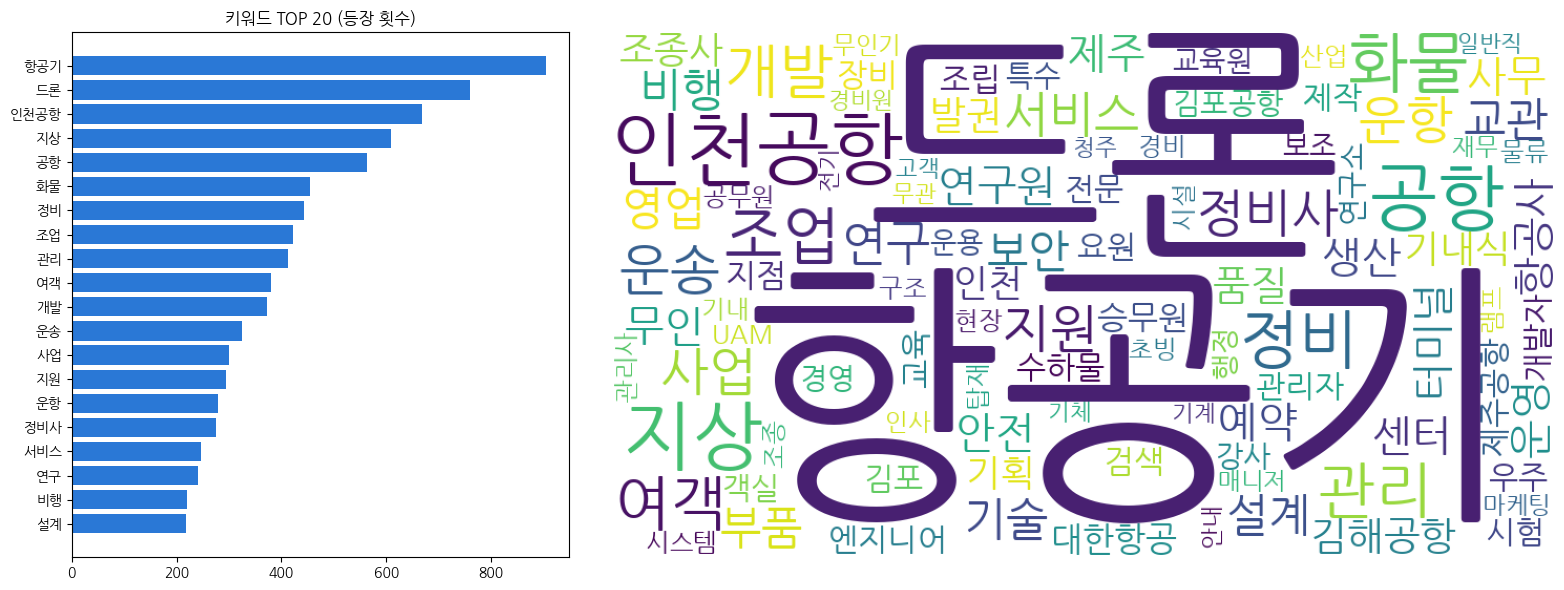

In [ ]:
import os                                       # 파일 경로를 다루는 도구
from collections import Counter                 # 개수 세기 도구
import matplotlib.pyplot as plt                 # 그래프 그리는 도구
import koreanize_matplotlib                     # 불러오기만 하면 그래프 한글 글꼴(나눔고딕)이 설정됨
from wordcloud import WordCloud                 # 워드클라우드 그리는 도구

# 모든 공고의 키워드를 펼쳐서 세기
#   for kws in df["키워드"] : 공고마다 키워드 목록을 꺼냄
#   for w in kws            : 그 목록 안의 키워드를 하나씩 꺼냄
#   Counter(…)              : 키워드별 등장 횟수를 셈 (예: {'항공기': 906, …})
count = Counter(w for kws in df["키워드"] for w in kws)
# 가장 많이 나온 키워드 20개 → {키워드: 횟수} 사전 → pd.Series(이름표가 달린 숫자 목록)
top20 = pd.Series(dict(count.most_common(20)))

# 그림 2칸 (왼쪽: TOP 20 막대, 오른쪽: 워드클라우드) — width_ratios: 칸 너비 비율
#   figsize=(16, 6) : 그림 전체 크기 (가로 16, 세로 6 인치)
#   axes[0], axes[1] : 왼쪽 칸, 오른쪽 칸
fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1, 2]})
# 왼쪽 칸에 가로 막대 그리기 (barh: 가로 막대, 이름표와 값을 [::-1]로 뒤집어 큰 값이 위로)
axes[0].barh(top20.index[::-1], top20.values[::-1], color="#2a78d6")     # [::-1]: 큰 값이 위로
# 왼쪽 칸 제목
axes[0].set_title("키워드 TOP 20 (등장 횟수)")

# 워드클라우드 (koreanize_matplotlib 안의 나눔고딕 글꼴 경로를 알려 줘야 한글이 나옴)
#   koreanize_matplotlib.__file__ : 이 도구 파일이 있는 경로
#   os.path.dirname(…)            : 그 파일이 들어 있는 폴더 경로
#   os.path.join(폴더, "fonts", "NanumGothic.ttf") : 폴더/fonts/NanumGothic.ttf 경로 만들기
font_path = os.path.join(os.path.dirname(koreanize_matplotlib.__file__), "fonts", "NanumGothic.ttf")
# WordCloud 설정
#   width, height       : 그림 크기 (픽셀)
#   background_color    : 배경색
#   max_words=100       : 많이 나온 키워드 100개까지만 표시
#   colormap="viridis"  : 글자 색 묶음
#   random_state=42     : 실행할 때마다 같은 배치가 나옴
#   .generate_from_frequencies(count) : {키워드: 횟수}로 글자 크기를 정해 그림 만들기
wc = WordCloud(font_path=font_path, width=900, height=500, background_color="white",
               max_words=100, colormap="viridis", random_state=42).generate_from_frequencies(count)
# 오른쪽 칸에 워드클라우드 그림 표시
axes[1].imshow(wc)
axes[1].axis("off")                              # 눈금·테두리 숨기기
plt.tight_layout()                               # 두 칸이 겹치지 않게 간격 자동 조정
plt.show()                                       # 그림 화면에 출력

✅ **결과 확인:** `항공기`, `드론`, `지상`, `공항`, `인천공항`, `정비`처럼 **항공 분야 직무와 근무지**가 위에 있습니다.

### 3-2. 2-gram: 붙어 나오는 두 키워드
`지상 조업`, `무인 항공기`처럼 두 단어가 붙어야 뜻이 분명해지는 직무 이름을 찾습니다.

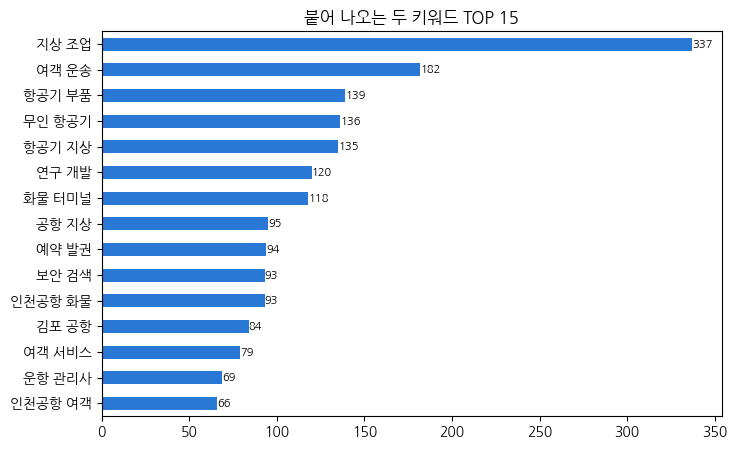

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer   # 단어(묶음) 개수를 세서 표로 만드는 도구

# 키워드 목록을 띄어쓰기로 이은 글자 (CountVectorizer 입력용)
#   예: ['지상', '조업'] → '지상 조업'
df["키워드문자열"] = df["키워드"].str.join(" ")

# 두 키워드 묶음 세기 (token_pattern=r"\S+": 띄어쓰기로 나뉜 덩어리를 한 단어로, ngram_range=(2, 2): 두 단어 묶음만)
#   lowercase=False : 영어를 소문자로 바꾸지 않음 (UAM 그대로)
bigram = CountVectorizer(token_pattern=r"\S+", ngram_range=(2, 2), lowercase=False)
# fit_transform : 모든 공고에서 두 단어 묶음 목록을 만들고(fit), 공고 × 묶음 개수 표 B로 바꿈(transform)
B = bigram.fit_transform(df["키워드문자열"])
# 묶음별 전체 개수 TOP 15
#   B.sum(axis=0)                   : 열(묶음)마다 모든 공고의 개수를 더함
#   .A1                             : 1줄짜리 배열로
#   bigram.get_feature_names_out()  : 열 순서대로 묶음 이름 (예: '지상 조업')
#   .nlargest(15)                   : 값이 큰 15개
top_bigram = pd.Series(B.sum(axis=0).A1, index=bigram.get_feature_names_out()).nlargest(15)   # .A1: 1줄짜리 배열로

# 가로 막대 그래프 ([::-1]: 큰 값이 위로, figsize: 그림 크기)
ax = top_bigram[::-1].plot.barh(color="#2a78d6", figsize=(8, 5))
ax.bar_label(ax.containers[0], fontsize=8)       # 막대 끝에 숫자
ax.set_title("붙어 나오는 두 키워드 TOP 15")     # 그래프 제목
plt.show()                                       # 그림 화면에 출력

### 3-3. 직무별 공고 수

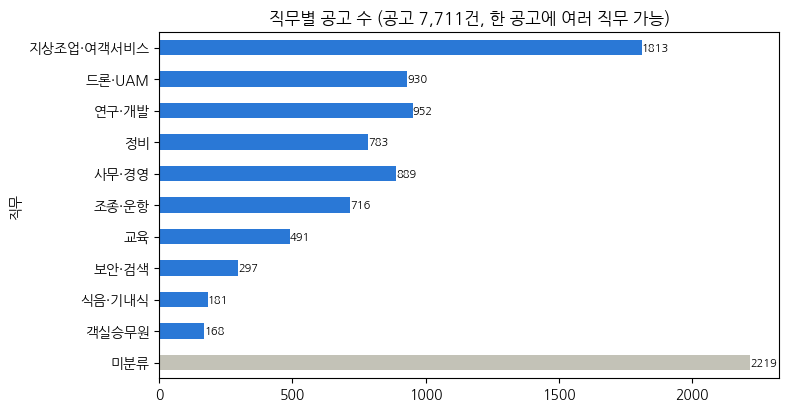

직무가 2개 이상 붙은 공고: 19.9%
미분류 공고: 28.8%


In [ ]:
# 직무 목록을 펼쳐서(explode) 직무별 개수 세기 → ORDER 순서로
#   .explode()        : 목록 한 칸을 여러 줄로 펼침 (['드론·UAM', '교육'] → 두 줄)
#   .value_counts()   : 직무별 개수
#   .reindex(ORDER)   : ORDER 순서로 다시 늘어놓음 (없는 직무는 NaN)
#   .fillna(0)        : NaN을 0으로
#   .astype(int)      : 정수로 바꿈
job_count = df["직무"].explode().value_counts().reindex(ORDER).fillna(0).astype(int)

# 가로 막대 (미분류는 회색)
#   ["#2a78d6"] * len(JOBS) : 직무 개수만큼 파란색,  + ["#c3c2b7"] : 맨 끝(미분류)은 회색
colors = ["#2a78d6"] * len(JOBS) + ["#c3c2b7"]
# 막대 순서와 색 순서를 둘 다 [::-1]로 뒤집어서 ORDER 첫 직무가 맨 위에 오게 그림
ax = job_count[::-1].plot.barh(color=colors[::-1], figsize=(8, 4.5))
ax.bar_label(ax.containers[0], fontsize=8)                                # 막대 끝에 숫자
# 그래프 제목 (f"…{len(df):,}…": 전체 공고 수를 천 단위 쉼표로 넣음)
ax.set_title(f"직무별 공고 수 (공고 {len(df):,}건, 한 공고에 여러 직무 가능)")
plt.show()                                                                # 그림 화면에 출력

# 직무가 2개 이상인 공고 비율
#   df['직무'].str.len() >= 2 : 직무 목록 길이가 2 이상이면 True
#   .mean()                   : True의 비율 (True=1, False=0의 평균),  :.1% → 소수 첫째 자리 퍼센트
print(f"직무가 2개 이상 붙은 공고: {(df['직무'].str.len() >= 2).mean():.1%}")
# 미분류 공고 비율 (직무 목록의 첫 번째 값이 '미분류'인 공고의 비율)
print(f"미분류 공고: {(df['직무'].str[0] == '미분류').mean():.1%}")

✅ **결과 확인:**
- **지상조업·여객서비스**가 가장 많고, **드론·UAM**과 **연구·개발**이 그 뒤를 잇습니다.
- 미분류는 `신입/경력사원 채용`처럼 **직무 단서가 없는 제목**입니다. 직무를 알려면 공고 본문이 필요합니다.
- 여러 직무를 허용했기 때문에 막대를 모두 더하면 전체 공고 수보다 큽니다.

### 3-4. 직무별 대표 키워드 (TF-IDF)
직무마다 공고 키워드를 이어 붙여 '직무 문서'를 만들고, **다른 직무보다 특히 많이 나온 키워드**를 뽑습니다.

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer   # TF-IDF 점수 표를 만드는 도구

# 직무별 문서 만들기: 공고를 직무별로 펼친 뒤(explode) 직무마다 키워드문자열을 이어 붙임
#   .explode("직무", ignore_index=True) : 직무 목록을 여러 줄로 펼치고 행 번호를 새로 매김
#   .groupby("직무")["키워드문자열"]    : 직무가 같은 줄끼리 묶어서 키워드문자열 열만 봄
#   .apply(" ".join)                    : 묶음마다 키워드문자열을 공백으로 이어 한 글자로 ('직무 문서')
#   .reindex(ORDER)                     : ORDER 순서로 다시 늘어놓음
by_job = df.explode("직무", ignore_index=True).groupby("직무")["키워드문자열"].apply(" ".join).reindex(ORDER)

# TF-IDF (analyzer=str.split: 이미 나눠 둔 키워드 그대로, sublinear_tf=True: 많이 나온 횟수를 log로 줄임)
tfidf_job = TfidfVectorizer(analyzer=str.split, sublinear_tf=True)
# fit_transform : 직무 문서 11개 × 키워드 점수 표를 만들고, .toarray()로 보통 숫자 배열로 바꿈
M = tfidf_job.fit_transform(by_job).toarray()
# 열 순서대로 키워드 이름
names = tfidf_job.get_feature_names_out()

# 직무마다 점수 큰 키워드 6개 (argsort()[::-1][:6]: 큰 순서로 위치 6개)
#   for row in M                  : 직무 한 줄(키워드 점수 목록)씩 꺼냄
#   names[…]                      : 위치 6개에 해당하는 키워드 이름
#   ", ".join(…)                  : 쉼표로 이은 한 글자
#   index=by_job.index            : 행 이름을 직무 이름으로
pd.DataFrame({"대표 키워드": [", ".join(names[row.argsort()[::-1][:6]]) for row in M]}, index=by_job.index)

,대표 키워드
직무,
지상조업·여객서비스,"라운지, 수하물, 상담사, 취급, 발권, 외항사"
드론·UAM,"드론, UAM, 설계, 무인, 연구, 장치"
연구·개발,"연구, 설계, 연구소, 드론, 개발, 연구원"
정비,"항공정비사, 정비사, 엔진, 기체, 정비, 차량"
사무·경영,"영업부, 경영, 회계, 구매, 재무, 인사"
조종·운항,"기장, 부기, 비행, 장치, 드론, 조종"
교육,"드론, 비행, 교육원, 교원, 교관, 학기"
보안·검색,"경비, 검색, 보안, 경비원, 청사, 화물"
식음·기내식,"케이터링, 기내식, 조리사, 조리, 탑재, 운전원"


✅ **결과 확인:** 직무 사전에 넣은 말(예: `정비`) 말고도 `항공정비사`(정비), `외항사`(지상조업), `케이터링`(식음·기내식) 같은 **함께 나오는 말**이 보이나요? 이런 말을 찾아 직무 사전에 추가하면 미분류를 줄일 수 있습니다.

---
## 4. 분석 결과
| 번호 | 결과 |
|---|---|
| 4-1 | 연도별 직무 비율 변화 |
| 4-2 | 연도별 특징 키워드 |
| 4-3 | 지역 × 직무 |
| 4-4 | 고용형태 (신입·경력 …) |
| 4-5 | 공고가 많은 회사 TOP 10 |

### 4-1. 연도별 직무 비율 변화
연도마다 공고 수가 크게 달라서, 건수가 아니라 **그 해 공고 중 비율(%)**로 봅니다. (공고가 5건뿐인 2018년은 뺍니다.)

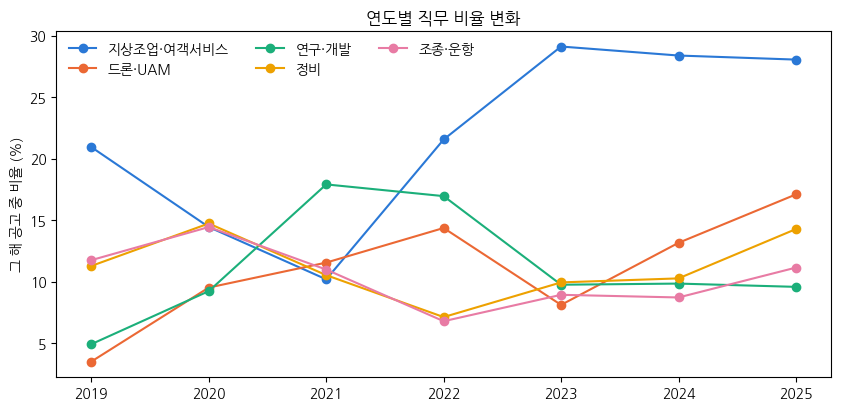

연도별 공고 수: {'2019': 425, '2020': 346, '2021': 882, '2022': 2087, '2023': 1587, '2024': 1420, '2025': 959}


In [ ]:
# 공고를 직무별로 펼침 → 연도 × 직무 개수 표 (crosstab) → 연도별 공고 수로 나눠 비율(%)
#   df[df["연도"] >= "2019"]       : 2019년 이후 공고만 (연도는 글자라서 "2019"와 글자로 비교)
#   .explode("직무", ignore_index=True) : 직무 목록을 여러 줄로 펼치고 행 번호를 새로 매김
jobs_long = df[df["연도"] >= "2019"].explode("직무", ignore_index=True)
# pd.crosstab(행, 열) : 연도(행) × 직무(열)마다 줄 개수를 센 표
table = pd.crosstab(jobs_long["연도"], jobs_long["직무"])
# 연도별 공고 수 (펼치기 전 df에서 셈, sort_index: 연도 순서대로)
year_total = df[df["연도"] >= "2019"]["연도"].value_counts().sort_index()      # 연도별 공고 수
# 비율(%) = 개수 ÷ 그 해 공고 수 × 100
ratio = table.div(year_total, axis=0) * 100                                    # div: 행마다 그 해 공고 수로 나누기

# ✏️ 볼 직무 (너무 많으면 선이 겹쳐서 5개만)
SHOW = ["지상조업·여객서비스", "드론·UAM", "연구·개발", "정비", "조종·운항"]
# 직무 5개에 순서대로 칠할 색
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]

# SHOW 직무 열만 골라 꺾은선 그래프 (marker="o": 점 표시, figsize: 그림 크기)
ax = ratio[SHOW].plot(color=COLORS, marker="o", figsize=(10, 4.5))
ax.set_ylabel("그 해 공고 중 비율 (%)")                  # 세로축 이름
ax.set_xlabel("")                                       # 가로축 이름 비우기
ax.set_title("연도별 직무 비율 변화")                    # 그래프 제목
# 범례: 왼쪽 위, 3열로 늘어놓기, 테두리 없음
ax.legend(loc="upper left", ncol=3, frameon=False)
plt.show()                                              # 그림 화면에 출력

# 연도별 공고 수를 {연도: 공고 수} 사전 모양으로 출력
print("연도별 공고 수:", year_total.to_dict())

✅ **결과 확인:**
- **지상조업·여객서비스**는 2021년 이후 크게 늘었습니다. 코로나19로 줄었던 항공 여객이 회복되면서 공항 인력을 다시 뽑은 흐름으로 **해석할 수 있습니다**(데이터만으로 원인을 확정할 수는 없음).
- **연구·개발**은 2021~2022년에 높았다가 내려갔고, **드론·UAM**은 2023년에 잠시 줄었다가 2024~2025년에 다시 늘었습니다.
- ⚠️ 해마다 공고를 올린 회사 구성이 다르기 때문에, 이 변화가 곧 **항공 채용 시장 전체의 변화라고 단정할 수는 없습니다.**

### 4-2. 연도별 특징 키워드
연도마다 키워드를 이어 붙여 '연도 문서'를 만들고 TF-IDF로 **그 해에 특히 많이 나온 키워드**를 뽑습니다.

In [ ]:
# 연도별 문서 → TF-IDF (max_df=0.6: 60%가 넘는 연도에 공통으로 나오는 키워드는 빼기 → 그 해만의 특징이 드러남)
#   df[df["연도"] >= "2019"]                 : 2019년 이후 공고만
#   .groupby("연도")["키워드문자열"].apply(" ".join) : 연도마다 키워드문자열을 공백으로 이어 한 글자로 ('연도 문서')
by_year = df[df["연도"] >= "2019"].groupby("연도")["키워드문자열"].apply(" ".join)
# TF-IDF 설정 (analyzer=str.split: 이미 나눠 둔 키워드 그대로, sublinear_tf=True: 횟수를 log로 줄임)
tfidf_year = TfidfVectorizer(analyzer=str.split, sublinear_tf=True, max_df=0.6)
# 연도 문서 × 키워드 점수 표 → 보통 숫자 배열
Y = tfidf_year.fit_transform(by_year).toarray()
# 열 순서대로 키워드 이름
ynames = tfidf_year.get_feature_names_out()

# 연도마다 점수 큰 키워드 7개를 쉼표로 이어 표로 보여 주기 (행 이름: 연도)
pd.DataFrame({"특징 키워드": [", ".join(ynames[row.argsort()[::-1][:7]]) for row in Y]}, index=by_year.index)

,특징 키워드
연도,
2019,"신뢰, 맞춤, 신세계, 학년도, 출연, 참여자, KOREAN"
2020,"파라다이스시티, JET, 주식회사, REPRESENTATIVE, 면장, 드론개발, ..."
2021,"정기, 전력, CMM, 조교, 영접, 총괄, 자동차"
2022,"경리, 제주항공, 도로, 게이트웨이, 안내원, 대상, 상담사"
2023,"펀드, PROJECT, 텍스, 나리타, 인도장, RAY, 검역"
2024,"학년, 전반기, GSA, 이스타항공, 서울역, CX, 탐지"
2025,"국적사, 지사, RESEARCHER, 예방, GSA, 충돌, MHB"


✅ **결과 확인:** 특정 연도에만 나온 사업 이름·기관 이름·직무가 보이나요? 그 해에 **어떤 회사가 공고를 많이 냈는지**에 크게 좌우된다는 점도 함께 생각해 보세요.

### 4-3. 지역 × 직무
공고가 많은 지역 6곳에서 직무 비율을 비교합니다. 숫자는 **그 지역 공고 중 비율(%)**입니다.

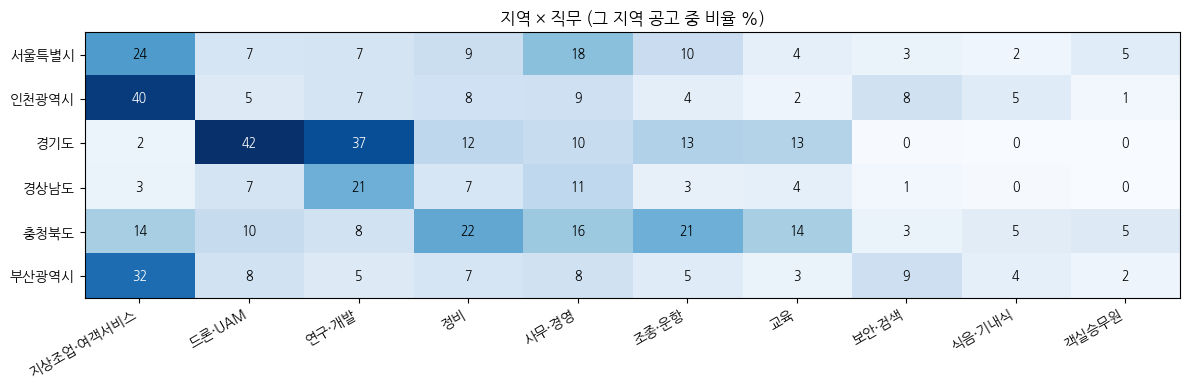

In [ ]:
# 공고가 많은 지역 6곳
#   value_counts() : 지역별 공고 수 (많은 순),  .head(6).index : 위에서 6개 지역 이름
top_regions = df["지역"].value_counts().head(6).index

# 지역 × 직무 개수 → 지역별 공고 수로 나눠 비율(%), 미분류는 빼고 ORDER 순서로
#   df["지역"].isin(top_regions) : 지역이 6곳 중 하나인 공고만 True
#   .explode("직무", ignore_index=True) : 직무 목록을 여러 줄로 펼치고 행 번호를 새로 매김
region_long = df[df["지역"].isin(top_regions)].explode("직무", ignore_index=True)
# 지역(행) × 직무(열) 개수 표 → 행은 top_regions 순서, 열은 JOBS 순서 (JOBS에 없는 '미분류'는 빠짐)
rt = pd.crosstab(region_long["지역"], region_long["직무"]).reindex(index=top_regions, columns=list(JOBS))
# 비율(%) = 개수 ÷ 그 지역 공고 수 × 100 (axis=0: 행마다 나누기)
rt = rt.div(df["지역"].value_counts()[top_regions], axis=0) * 100

# 색 표(heatmap): imshow로 숫자 표를 색으로 칠하고, 칸마다 숫자 쓰기
fig, ax = plt.subplots(figsize=(12, 4))                     # 그림 1칸 (가로 12, 세로 4 인치)
# rt.values : 숫자 배열,  cmap="Blues": 값이 클수록 진한 파랑,  aspect="auto": 칸 모양을 그림 크기에 맞춤
ax.imshow(rt.values, cmap="Blues", aspect="auto")
# 가로축 눈금 위치와 이름(직무), 30도 기울이고 오른쪽 끝을 눈금에 맞춤
ax.set_xticks(range(len(rt.columns)), rt.columns, rotation=30, ha="right")
# 세로축 눈금 위치와 이름(지역)
ax.set_yticks(range(len(rt.index)), rt.index)
for i in range(rt.shape[0]):                       # 행(지역)마다
    for j in range(rt.shape[1]):                   # 열(직무)마다
        v = rt.values[i, j]                        # i행 j열의 비율 값
        # 칸 가운데(j, i)에 값을 소수점 없이(:.0f) 쓰기
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=9,
                color="white" if v > rt.values.max() * 0.6 else "black")   # 진한 칸은 흰 글씨
ax.set_title("지역 × 직무 (그 지역 공고 중 비율 %)")       # 그래프 제목
plt.tight_layout()                                           # 글자가 잘리지 않게 간격 자동 조정
plt.show()                                                   # 그림 화면에 출력

✅ **결과 확인:** **인천·부산**은 지상조업·여객서비스(공항), **경기**는 드론·UAM과 연구·개발, **경남**은 연구·개발(항공기 제조 기업), **충북**은 정비와 조종·운항 비율이 높게 나오나요? 지역마다 항공 산업의 성격이 다르게 드러납니다.

### 4-4. 고용형태 (신입·경력 …)
제목에 고용형태 표현이 **있는 공고만** 셉니다. (한 공고에 `신입, 경력`처럼 여러 개 가능)

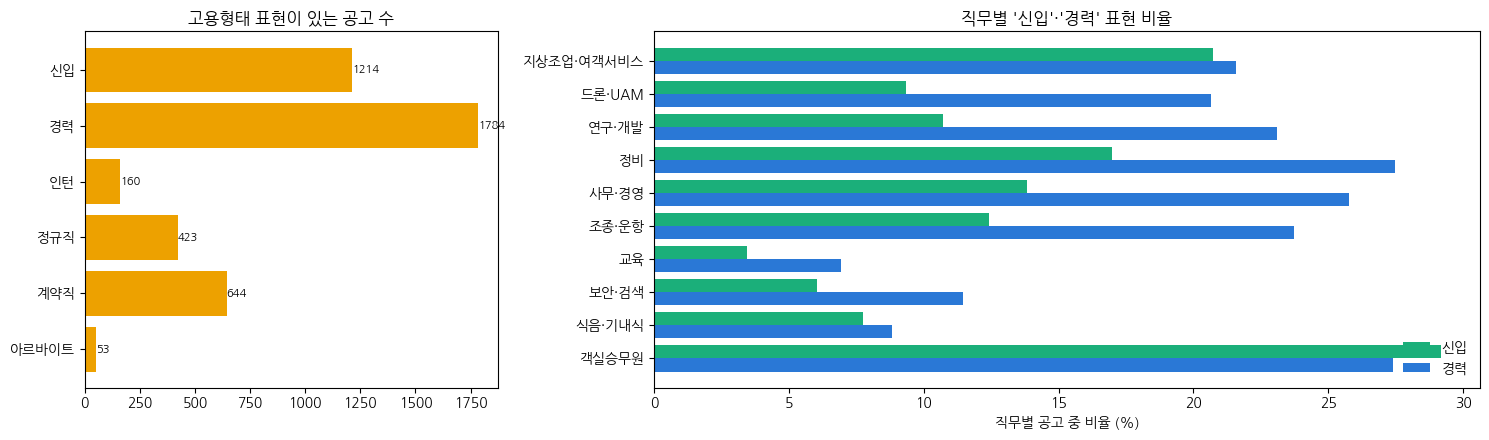

In [ ]:
# 고용형태 목록 만들기: 쉼표로 이은 글자 → 목록 → 펼쳐서 세기 (빈 글자는 빼기)
#   .str.split(", ") : '신입, 경력' → ['신입', '경력'],  빈 글자 → ['']
#   .explode()       : 목록을 여러 줄로 펼침
employ = df["고용형태"].str.split(", ").explode()
# 빈 글자가 아닌 줄만 세고(value_counts), EMPLOY 사전 순서로 다시 늘어놓기
employ_count = employ[employ != ""].value_counts().reindex(list(EMPLOY))

# 직무별 '신입' 표현 비율과 '경력' 표현 비율 (직무별 공고 중 %)
#   job_long : 직무 목록을 여러 줄로 펼친 표
job_long = df.explode("직무", ignore_index=True)
# 직무마다 고용형태에 '신입'이 들어 있는 줄의 비율 × 100, JOBS 순서로 (미분류는 빠짐)
#   s.str.contains("신입") : 글자 안에 '신입'이 있으면 True,  .mean() : True의 비율
newbie = job_long.groupby("직무")["고용형태"].apply(lambda s: s.str.contains("신입").mean() * 100).reindex(list(JOBS))
# 직무마다 고용형태에 '경력'이 들어 있는 줄의 비율 × 100, JOBS 순서로
career = job_long.groupby("직무")["고용형태"].apply(lambda s: s.str.contains("경력").mean() * 100).reindex(list(JOBS))

# 그림 2칸 (왼쪽 : 오른쪽 너비 = 1 : 2)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [1, 2]})
# (왼쪽) 고용형태별 공고 수
#   [::-1] : EMPLOY 첫 항목(신입)이 맨 위에 오게 뒤집어서 그림
axes[0].barh(employ_count.index[::-1], employ_count.values[::-1], color="#eda100")
axes[0].bar_label(axes[0].containers[0], fontsize=8)     # 막대 끝에 숫자
axes[0].set_title("고용형태 표현이 있는 공고 수")         # 왼쪽 칸 제목
# (오른쪽) 직무별 신입·경력 비율 (막대 두 개를 위아래로 조금씩 비켜 그림)
#   y : 직무 위치 번호 0, 1, 2, …
y = range(len(JOBS))
# 신입 막대: 위치에서 0.2 위로, 막대 두께 0.4
axes[1].barh([i - 0.2 for i in y], newbie.values, height=0.4, color="#1baf7a", label="신입")
# 경력 막대: 위치에서 0.2 아래로, 막대 두께 0.4
axes[1].barh([i + 0.2 for i in y], career.values, height=0.4, color="#2a78d6", label="경력")
# 세로축 눈금 위치(0, 1, 2, …)에 직무 이름 붙이기
axes[1].set_yticks(list(y), list(JOBS))
axes[1].invert_yaxis()                              # 위에서부터 JOBS 순서대로
axes[1].set_xlabel("직무별 공고 중 비율 (%)")        # 가로축 이름
axes[1].set_title("직무별 '신입'·'경력' 표현 비율")  # 오른쪽 칸 제목
axes[1].legend(loc="lower right", frameon=False)    # 범례: 오른쪽 아래, 테두리 없음
plt.tight_layout()                                  # 두 칸이 겹치지 않게 간격 자동 조정
plt.show()                                          # 그림 화면에 출력

✅ **결과 확인:** 어떤 직무가 **신입에게 문이 넓은지**(신입 비율이 경력보다 높은 직무), 어떤 직무가 **경력 위주**인지 보세요. 단, 제목에 신입·경력을 적지 않은 공고가 많아서, 비율은 '표현이 있는 공고' 기준입니다.

### 4-5. 공고가 많은 회사 TOP 10

In [ ]:
# 회사별 공고 수 TOP 10 (반복 공고를 지운 뒤)
#   value_counts() : 회사별 공고 수 (많은 순),  .head(10) : 위에서 10곳
top_company = df["회사"].value_counts().head(10)

# 회사마다 가장 많은 직무 (미분류 제외) 찾기
#   df["회사"].isin(top_company.index)  : TOP 10 회사의 공고만 고르기
#   .explode("직무", ignore_index=True) : 직무 목록을 여러 줄로 펼치기
main_job = (df[df["회사"].isin(top_company.index)].explode("직무", ignore_index=True)
            .query("직무 != '미분류'")                                       # 미분류 줄 빼기
            .groupby("회사")["직무"].agg(lambda s: s.value_counts().index[0]))  # 가장 많은 직무 이름

# 공고 수와 가장 많은 직무를 나란히 놓은 표 (main_job을 top_company 순서로 맞춤)
pd.DataFrame({"공고 수": top_company, "가장 많은 직무": main_job.reindex(top_company.index)})

,공고 수,가장 많은 직무
회사,,
샤프에비에이션케이,228,지상조업·여객서비스
에어로케이,157,사무·경영
에어프레미아,133,사무·경영
제주항공,126,사무·경영
스위스포트코리아,97,지상조업·여객서비스
에어인천,87,사무·경영
에이티에스,86,지상조업·여객서비스
남부공항서비스,79,사무·경영
KAC공항서비스,71,사무·경영


---
## 정리

### ✅ 한 줄 정리
**채용공고 제목에서 태그·고용형태·지역을 뽑고, 반복 공고를 지운 뒤, 키워드와 직무 사전으로 항공 분야의 직무 분포·연도별 변화·지역 차이·신입/경력 비율을 살펴봤다.**

### 🗂️ 만든 파일
| 파일 | 내용 |
|---|---|
| `job_dataset.csv` | 정제 데이터셋 (연도, 회사, 지역, 원래 제목, 정리된 제목, 태그, 고용형태, 키워드, 직무) |

### 🤔 생각해 볼 점 (한계)
| 한계 | 설명 |
|---|---|
| **제목만 있음** | 자격요건·급여·근무조건은 알 수 없습니다. 직무 단서가 없는 제목은 미분류로 남습니다. |
| **공고 수 ≠ 채용 인원** | 공고 1건에 여러 명을 뽑을 수도, 한 명도 안 뽑을 수도 있습니다. |
| **반복 공고 기준** | '회사+제목이 같으면 같은 공고'로 봤습니다. 실제로는 해마다 새로 뽑는 공고일 수도 있습니다. |
| **사전은 사람이 정함** | `JOBS`, `EMPLOY`, `STOP`을 바꾸면 결과가 바뀝니다. 특히 `상담`, `화물`을 지상조업·여객서비스에 넣은 것은 하나의 판단입니다. |
| **데이터에 들어온 회사가 해마다 다름** | 연도별 변화가 시장 변화인지, 이 자료에 공고를 올린 회사가 바뀐 것인지 구분할 수 없습니다. |



**참고:** [Kiwi (kiwipiepy)](https://github.com/bab2min/kiwipiepy) · [scikit-learn 텍스트 특징 추출](https://scikit-learn.org/stable/modules/feature_extraction.html#text-feature-extraction) · [wordcloud](https://github.com/amueller/word_cloud)